# Notebook 9 – Data Transformation
## `09_Data_Transformation.ipynb`

### Learning objectives
Understand why data is transformed, apply common mathematical transformations, handle skewed numeric data, and compare distributions before and after transformation.

**Why preprocessing is required:** Real datasets may contain highly skewed numeric features, long tails, or values with very different distributions. Some statistical and machine-learning methods work better when numeric features are less skewed or closer to a suitable distribution. Transformation can reduce skewness, stabilize variance, and make patterns easier for some models to learn.

**Important:** A transformation does not guarantee a normal distribution and does not fix data-quality errors. Choose a method based on the data and the model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    FunctionTransformer, PowerTransformer, StandardScaler, MinMaxScaler
)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Simple example, real-world example, and business use case

We create a positively skewed feature representing customer monthly spending. Most customers spend modest amounts, while a small number spend much more.

- **Simple example:** Transform values such as 10, 20, 30, and 500 to reduce the effect of a long right tail.
- **Real-world example:** Household income, transaction amounts, house prices, and website session durations are often right-skewed.
- **Business example:** A retailer studies customer spending. A few very high spenders can make the raw distribution difficult to summarize.
- **AI/ML use case:** A log or power transformation may help linear or regression models represent a relationship more effectively. Tree models often need less transformation.

In [2]:
rng = np.random.default_rng(42)
spending = rng.lognormal(mean=3.0, sigma=0.8, size=500)

df = pd.DataFrame({"Monthly_Spending": spending})
display(df.head())
print(df["Monthly_Spending"].describe())
print("Skewness:", round(df["Monthly_Spending"].skew(), 3))

,Monthly_Spending
0,25.630
1,8.741
2,36.611
3,42.625
4,4.217


count   500.000
mean     26.847
std      24.717
min       2.577
25%      11.781
50%      20.137
75%      32.134
max     206.663
Name: Monthly_Spending, dtype: float64
Skewness: 3.075


## 2. Why transform data?

Transformation changes the mathematical representation of a feature while preserving the observations' meaning as far as the chosen function allows.

It can help:
- Reduce strong right or left skewness.
- Make variance more stable across the range.
- Reduce the influence of very large positive values.
- Make linear relationships more suitable for certain models.
- Improve numerical behavior for some statistical procedures.

It may not help:
- Tree-based algorithms that can model nonlinear splits directly.
- Features where the transformation makes interpretation difficult.
- Data containing zeros or negative values when using a transformation that does not support them.

## 3. Inspect the distribution before transformation

A histogram shows the shape of a numeric distribution. Skewness is a numerical measure of asymmetry: positive values indicate a longer right tail; negative values indicate a longer left tail. A value near zero suggests symmetry but does not prove normality.

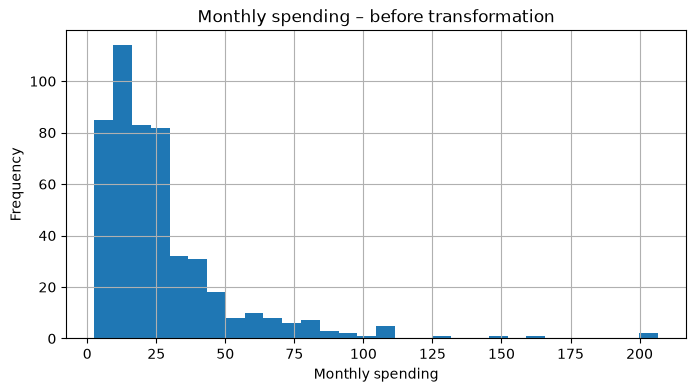

Before: skewness = 3.075


In [3]:
plt.figure(figsize=(8, 4))
plt.hist(df["Monthly_Spending"], bins=30)
plt.title("Monthly spending – before transformation")
plt.xlabel("Monthly spending")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

print("Before: skewness =", round(df["Monthly_Spending"].skew(), 3))

## 4. Log Transformation

Log transformation compresses large positive values more strongly than small values. It is useful for positive, right-skewed data.

- `np.log(x)` requires x > 0.
- `np.log1p(x)` calculates log(1 + x), so it can handle zero but not values below -1.
- Log transformation changes units and interpretation. For example, differences on the log scale correspond to ratios/multiplicative changes on the original scale.

**Problem it solves:** A few very large positive values can dominate the scale. Log transformation compresses the long right tail.

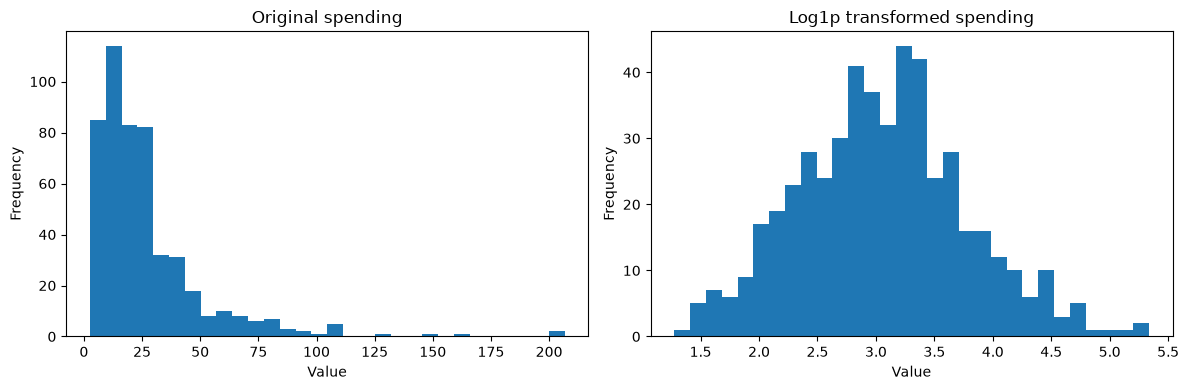

Original skewness: 3.075
Log1p skewness: 0.209


In [4]:
df["Log_Spending"] = np.log1p(df["Monthly_Spending"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Monthly_Spending"], bins=30)
axes[0].set_title("Original spending")
axes[1].hist(df["Log_Spending"], bins=30)
axes[1].set_title("Log1p transformed spending")
for ax in axes:
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Original skewness:", round(df["Monthly_Spending"].skew(), 3))
print("Log1p skewness:", round(df["Log_Spending"].skew(), 3))

## 5. Square Root Transformation

Square root transformation is less aggressive than log transformation for many positive values. It can reduce right skewness and is often used for non-negative count data.

**Requirement:** Values must be non-negative. If the feature contains negative values, investigate the meaning before applying a shift or another method.

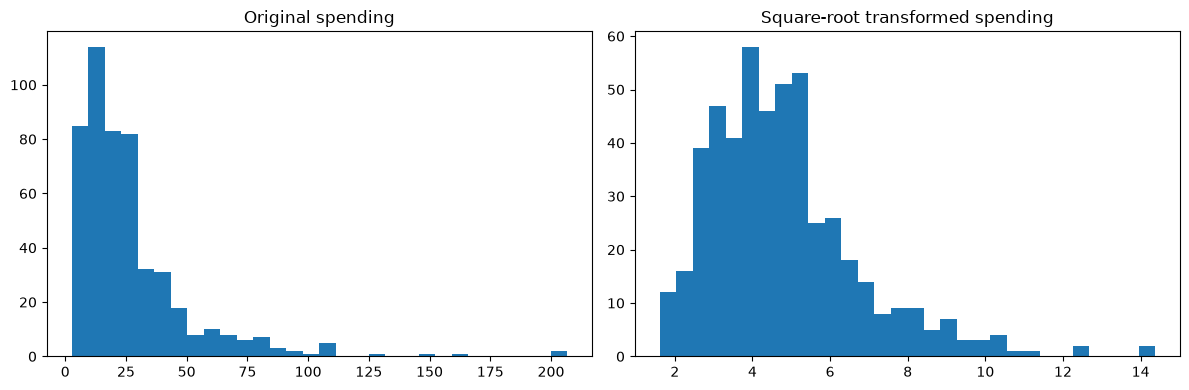

Square-root skewness: 1.351


In [5]:
df["Sqrt_Spending"] = np.sqrt(df["Monthly_Spending"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Monthly_Spending"], bins=30)
axes[0].set_title("Original spending")
axes[1].hist(df["Sqrt_Spending"], bins=30)
axes[1].set_title("Square-root transformed spending")
plt.tight_layout()
plt.show()

print("Square-root skewness:", round(df["Sqrt_Spending"].skew(), 3))

## 6. Power Transformation

Power transformations apply a mathematically selected power to make data more symmetric or stabilize variance. A power transformation is not one single formula; Box-Cox and Yeo-Johnson are common families.

In scikit-learn, `PowerTransformer` estimates the power parameter from the training data. By default, it standardizes the transformed output. Set `standardize=False` when you want to inspect only the power-transformed values.

In [6]:
power_only = PowerTransformer(method="yeo-johnson", standardize=False)
yeo_power_values = power_only.fit_transform(df[["Monthly_Spending"]]).ravel()
df["Power_Transformed"] = yeo_power_values

print("Power transformed skewness:", round(df["Power_Transformed"].skew(), 3))


Power transformed skewness: 0.004


## 7. Box-Cox Transformation

Box-Cox estimates a power parameter (lambda) to make positive data more symmetric.

**Requirement:** Every input value must be strictly positive. It cannot directly handle zero or negative values.

Use it when the feature is positive and a data-driven power transformation is appropriate. Do not add an arbitrary constant without considering the domain meaning.

In [7]:
boxcox_transformer = PowerTransformer(method="box-cox", standardize=False)
boxcox_values = boxcox_transformer.fit_transform(df[["Monthly_Spending"]]).ravel()
df["BoxCox_Spending"] = boxcox_values

print("Estimated Box-Cox lambda:", round(float(boxcox_transformer.lambdas_[0]), 3))
print("Box-Cox skewness:", round(df["BoxCox_Spending"].skew(), 3))

Estimated Box-Cox lambda: -0.042
Box-Cox skewness: 0.001


## 8. Yeo-Johnson Transformation

Yeo-Johnson is similar in purpose to Box-Cox but can handle positive, zero, and negative values. It estimates a power parameter from the data.

**When useful:** A feature contains zero or negative values and a power transformation is suitable. It is still important to check the resulting distribution and whether the transformation makes domain sense.

In [ ]:
signed_values = np.array([-20, -8, -3, 0, 1, 2, 5, 12, 30], dtype=float)
yeo = PowerTransformer(method="yeo-johnson", standardize=False)
signed_transformed = yeo.fit_transform(signed_values.reshape(-1, 1)).ravel()

yeo_demo = pd.DataFrame({
    "Original (includes negatives and zero)": signed_values,
    "Yeo-Johnson transformed": signed_transformed
})
display(yeo_demo.round(3))

## 9. Handling Skewed Data

Suggested workflow:

1. Check the histogram, box plot, and skewness.
2. Confirm values are valid; correct data-entry errors first.
3. Understand whether extreme values are genuine.
4. Choose a transformation that supports the feature's values (positive, non-negative, or signed).
5. Fit transformation parameters on training data only.
6. Compare before/after distributions and model performance.
7. Keep the original feature or document the transformation so results remain interpretable.

A transformation does not mean that outliers should automatically be removed.

In [ ]:
skewness_report = pd.DataFrame({
    "Feature": [
        "Original",
        "Log1p",
        "Square root",
        "Box-Cox",
        "Yeo-Johnson"
    ],
    "Skewness": [
        df["Monthly_Spending"].skew(),
        df["Log_Spending"].skew(),
        df["Sqrt_Spending"].skew(),
        df["BoxCox_Spending"].skew(),
        df["Power_Transformed"].skew()
    ]
})
display(skewness_report.round(3))

## 10. Compare distributions before and after transformation

The plots below use the same sample observations. A more symmetric histogram may be helpful for some models, but do not judge a transformation only by appearance. Check domain meaning, residual behavior, and validation performance too.

In [ ]:
plot_columns = [
    ("Monthly_Spending", "Original"),
    ("Log_Spending", "Log1p"),
    ("Sqrt_Spending", "Square root"),
    ("BoxCox_Spending", "Box-Cox"),
    ("Power_Transformed", "Yeo-Johnson")
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (column, title) in zip(axes.ravel(), plot_columns):
    ax.hist(df[column], bins=30)
    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

## 11. Normalization

In machine learning preprocessing, normalization often means scaling feature values to a fixed range, commonly 0 to 1. Here we use MinMaxScaler.

Normalization changes the range, not necessarily the distribution shape or skewness. It is different from log/power transformation.

In [ ]:
minmax = MinMaxScaler()
df["MinMax_Normalized"] = minmax.fit_transform(df[["Monthly_Spending"]]).ravel()

print(df[["Monthly_Spending", "MinMax_Normalized"]].head())
print("Normalized minimum:", round(df["MinMax_Normalized"].min(), 3))
print("Normalized maximum:", round(df["MinMax_Normalized"].max(), 3))

## 12. Standardization

Standardization subtracts the mean and divides by the standard deviation. The resulting training feature has mean approximately 0 and standard deviation approximately 1. It does not force the distribution to become normal and does not bound values to 0–1.

Use StandardScaler when an algorithm expects or benefits from comparable feature scales.

In [ ]:
standard = StandardScaler()
df["Standardized_Spending"] = standard.fit_transform(df[["Monthly_Spending"]]).ravel()

print(df[["Monthly_Spending", "Standardized_Spending"]].head())
print("Mean:", round(df["Standardized_Spending"].mean(), 6))
print("Standard deviation:", round(df["Standardized_Spending"].std(ddof=0), 6))

## 13. Compare normalization, standardization, and distribution transformation

- **Min-Max normalization:** changes feature range to 0–1; does not remove skewness.
- **Standardization:** centers and scales using mean and standard deviation; does not remove skewness.
- **Log/square-root/power transformation:** changes the shape of the distribution and may reduce skewness.
- These methods can sometimes be combined, for example a power transformation followed by standardization. Use a pipeline and fit on training data only.

In [ ]:
comparison_columns = [
    "Monthly_Spending", "Log_Spending", "Sqrt_Spending",
    "BoxCox_Spending", "Power_Transformed",
    "MinMax_Normalized", "Standardized_Spending"
]
display(df[comparison_columns].describe().T.round(3))

## 14. Real-world AI/ML preprocessing example with train/test split

This example demonstrates safe fitting: split first, fit the transformation using training rows only, then transform the test rows with the same fitted object. `PowerTransformer` estimates its parameters from training data.

In [ ]:
from sklearn.model_selection import train_test_split

# Use a reproducible synthetic feature and a numeric target for demonstration.
demo = pd.DataFrame({
    "Transaction_Amount": rng.lognormal(mean=3.0, sigma=0.9, size=300)
})
demo["Target"] = (demo["Transaction_Amount"] > demo["Transaction_Amount"].median()).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    demo[["Transaction_Amount"]], demo["Target"],
    test_size=0.2, random_state=42, stratify=demo["Target"]
)

transformer = PowerTransformer(method="yeo-johnson")
X_train_transformed = transformer.fit_transform(X_train)
X_test_transformed = transformer.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])
print("Transformed training mean:", round(float(X_train_transformed.mean()), 4))
print("Transformed training std:", round(float(X_train_transformed.std()), 4))

## 15. Common mistakes

1. Applying `np.log()` to zero or negative values.
2. Applying Box-Cox to data containing zero or negative values.
3. Assuming Yeo-Johnson or Box-Cox always produces a perfectly normal distribution.
4. Fitting a transformation on the full dataset before splitting (data leakage).
5. Transforming a categorical feature as if it were continuous numeric data.
6. Deleting valid high values instead of investigating them.
7. Forgetting that transformed values may be harder to explain to business users.
8. Using normalization and standardization as if they were distribution-shape transformations.

### Summary table

| Technique | Supports zero? | Supports negatives? | Main purpose |
|---|---:|---:|---|
| Log `log(x)` | No | No | Compress positive right tail |
| Log1p `log(1+x)` | Yes | Only if x > -1 | Compress non-negative values |
| Square root | Yes | No | Moderate compression for non-negative data |
| Box-Cox | No | No | Estimate power for positive data |
| Yeo-Johnson | Yes | Yes | Estimate power with signed data |
| Min-Max scaling | Yes | Yes | Scale range, often to 0–1 |
| Standardization | Yes | Yes | Center and scale |

### Final takeaway
Use transformation when the distribution shape is a concern; use normalization or standardization when feature scale is a concern. Always compare the original and transformed data, preserve domain meaning, and prevent data leakage.